# Independent Evaluation and Research Conclusions

## 1. Research objective

This study evaluates next-trading-session NVIDIA closing-price forecasts using a selected LSTM and engineered financial features. Three questions guide the independent assessment:

1. Can the selected LSTM outperform naïve persistence and ARIMA?
2. Do technical indicators improve LSTM forecasting accuracy?
3. Does SPY/XLK market context provide additional value?

The comparison includes **naïve persistence**, **ARIMA(2,1,2)**, **LSTM A: Close only**, **LSTM B: Close plus technical indicators**, and **LSTM C: B plus SPY/XLK log returns**. A is the prespecified primary LSTM. B and C test grouped feature contributions; they are not replacement models selected from test outcomes. [Notebook 04](04_lstm_experiments.ipynb) explains the residual LSTM and [Notebook 05](05_feature_experiments.ipynb) defines the features.

## 2. Independent evaluation methodology

Development used **2015–2022 for training** and **2023–2024 for validation**. After model specifications were frozen, final models were refitted on **2015–2024**, including newly fitted training-only scalers. The independent test covers **2 January–31 December 2025**. All models predict the next trading session's retrospectively split-adjusted Yahoo **Close in USD**, not dividend-adjusted Adj Close. Historical input and indicator context continue across the test boundary.

The 250 test sessions produce 2,750 forecasts: one naïve, one ARIMA and nine LSTM forecasts per session. LSTMs retain the approved architecture, training settings and seeds 42, 123 and 2026. Their weights and scalers remain fixed; ARIMA coefficients remain fixed while its filtered state updates after observation.

All forecasts for a target session are recorded before its actual prices are incorporated. Those newly observed prices may then inform the next one-step forecast. This rolling evaluation does not require predicting the entire year from December 2024. Every model uses identical target dates and metric definitions; no difficult dates are removed.

The following cells verify saved provenance and alignment. They read the preserved evaluation record and final-training manifest, without loading model checkpoints for inference, repeating forecasts or changing evidence. Hashes establish file identity; the saved sequencing checks and corresponding implementation tests support the forecast-before-observation safeguard.

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from market_forecasting.evaluation import (
    FORECAST_COLUMNS, SEEDS, VARIANTS, COMPARISONS,
    validate_evaluation_table, evaluate_predictions, paired_circular_bootstrap,
)
from market_forecasting.evaluation_plots import (
    plot_naive_relative_performance, plot_forecast_examples, select_forecast_examples,
)

ROOT = Path.cwd() if (Path.cwd() / "configs/nvda.json").exists() else Path.cwd().parent
BASE = ROOT / "artifacts/final_evaluation_v1"
record = json.loads((BASE / "evaluation.json").read_text())
manifest_path = ROOT / "artifacts/final_training_v1/manifest.json"
manifest = json.loads(manifest_path.read_text())
pd.options.display.float_format = "{:,.6f}".format
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

In [2]:
# Bind the saved results to the original models, configuration and evaluation source.
assert record["status"] == "verified" and record["scope"] == "independent_test"
assert manifest["status"] == "frozen"
assert hashlib.sha256(manifest_path.read_bytes()).hexdigest() == record["training_manifest_sha256"]
assert record["frozen_payload_sha256"] == manifest["artifacts_sha256"]
assert record["snapshot_sha256"] == manifest["snapshot_sha256"]
assert record["configuration"]["comparison"] == manifest["protocol"]["comparison"]
assert record["configuration"]["comparison"]["primary_lstm"] == "A"
assert record["configuration"]["seeds"] == list(SEEDS)
assert all(record["verification"].values())
expected_hashes = {
    **manifest["artifacts_sha256"],
    "artifacts/final_training_v1/manifest.json": record["training_manifest_sha256"],
    "artifacts/final_evaluation_v1/source.zip": record["evaluation_source_archive_sha256"],
    "configs/final_evaluation_v1.json": record["configuration_sha256"],
}
for relative, expected in expected_hashes.items():
    assert hashlib.sha256((ROOT / relative).read_bytes()).hexdigest() == expected, relative
watched_files = [BASE / "evaluation.json", *(ROOT / name for name in expected_hashes)]
watched_files += sorted((ROOT / "notebooks").glob("0[1-5]_*.ipynb"))
before_hashes = {p: hashlib.sha256(p.read_bytes()).hexdigest() for p in watched_files}
print("Verified frozen provenance; evaluation source revision:", record["evaluation_implementation"]["revision"])

Verified frozen provenance; evaluation source revision: dc56f099342218a64b87439bb98c3f6a110d1326


In [3]:
# Adapt the saved rows to the shared evaluator's table; no forecasts are regenerated.
table = validate_evaluation_table(pd.DataFrame([
    {"origin_date": row["origin_date"], "target_date": row["target_date"],
     "origin_close": row["origin_close"], "actual_close": row["observed_close"]["NVDA"],
     **row["predictions"]}
    for row in record["rows"]
]))
assert len(table) == record["execution"]["target_count"] == 250
assert len(table) * len(FORECAST_COLUMNS) == record["execution"]["forecast_count"] == 2750
assert table.origin_date.iloc[0] == pd.Timestamp("2024-12-31")
assert table.target_date.iloc[[0, -1]].tolist() == [pd.Timestamp("2025-01-02"), pd.Timestamp("2025-12-31")]
assert (table.origin_date < table.target_date).all()
for name in FORECAST_COLUMNS:
    errors = table[name].to_numpy() - table.actual_close.to_numpy()
    np.testing.assert_array_equal(errors, [row["errors"][name] for row in record["rows"]])
    np.testing.assert_array_equal(abs(errors), [row["absolute_errors"][name] for row in record["rows"]])
print("250 aligned sessions, 2,750 forecasts; recorded signed and absolute errors agree.")

250 aligned sessions, 2,750 forecasts; recorded signed and absolute errors agree.


## 3. Final model performance

MAE is the primary measure of typical absolute error; RMSE gives greater weight to large misses. Both are reported in USD. Skill is $100(1-E_{model}/E_{naive})$: positive values indicate improvement over persistence.

Each LSTM family is summarised by the arithmetic mean of its three seed-specific MAEs or RMSEs. Predictions are **not averaged into an ensemble**. The shared evaluation function reproduces the complete recorded metrics, including individual seeds, family aggregation and paired comparisons. Display rounding does not alter the underlying values.

In [4]:
metrics = evaluate_predictions(table)
assert metrics == record["metrics"]
family_rows = []
for name in ("naive", "ARIMA", *VARIANTS):
    if name in VARIANTS:
        row = metrics["families"][name]
        mae, rmse = row["mean_mae_usd"], row["mean_rmse_usd"]
        for metric in ("mae", "rmse"):
            seed_values = [metrics["per_model"][f"{name}_seed_{s}"][f"{metric}_usd"] for s in SEEDS]
            assert np.mean(seed_values) == row[f"mean_{metric}_usd"]
            assert np.std(seed_values, ddof=1) == row[f"sample_std_{metric}_usd"]
    else:
        row = metrics["per_model"][name]
        mae, rmse = row["mae_usd"], row["rmse_usd"]
    family_rows.append({"Model": "Naïve" if name == "naive" else name,
                        "MAE (USD)": mae, "RMSE (USD)": rmse,
                        "MAE skill (%)": row["percentage_skill"]["mae"]})
performance = pd.DataFrame(family_rows).set_index("Model")
display(performance)
print("MAE sample SD across seeds:", "; ".join(
    f"{v}: ${metrics['families'][v]['sample_std_mae_usd']:.5f}" for v in VARIANTS))

,MAE (USD),RMSE (USD),MAE skill (%)
Model,,,
Naïve,3.154681,4.290545,0.000000
ARIMA,3.110051,4.239547,1.414722
A,3.187466,4.310978,-1.039256
B,3.181817,4.325776,-0.860196
C,3.179046,4.315488,-0.772354


MAE sample SD across seeds: A: $0.02709; B: $0.03153; C: $0.01924


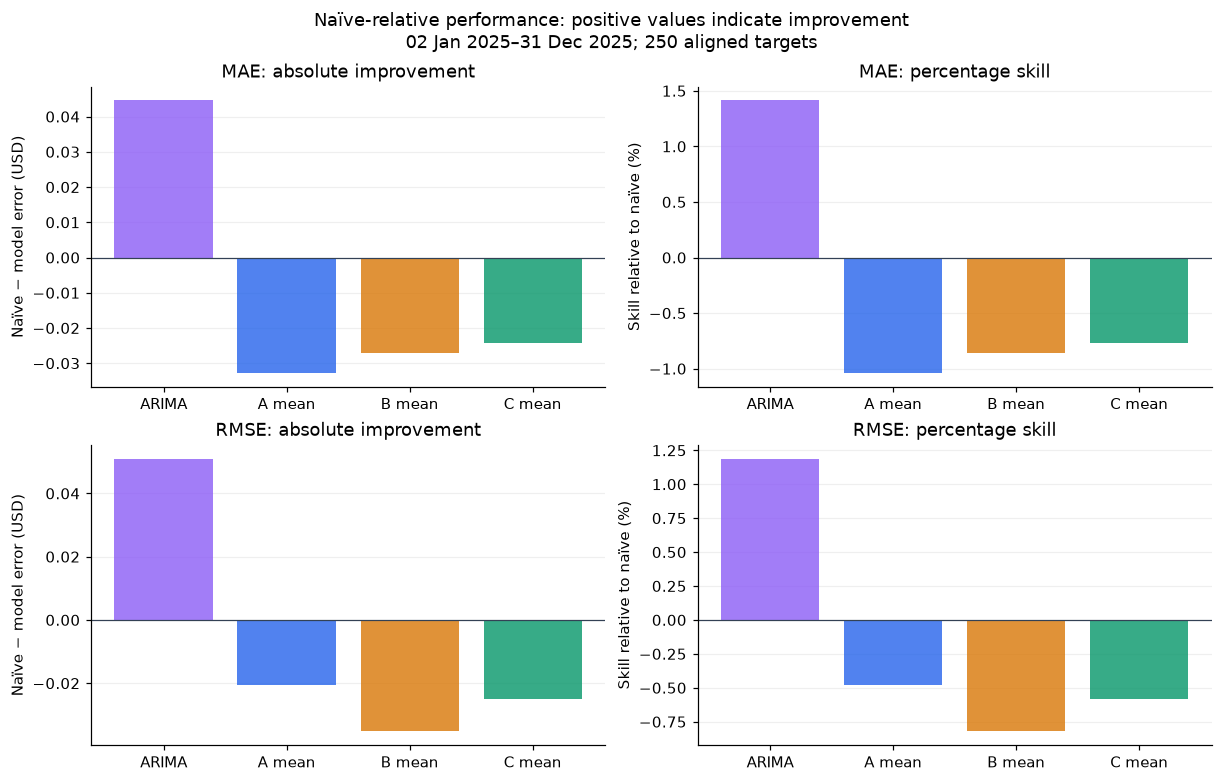

In [5]:
# The zero reference is naïve persistence; each LSTM bar represents a seed-metric mean.
plot_naive_relative_performance(table)
plt.show()

**Interpretation.** ARIMA has the lowest observed MAE (\$3.110051) and RMSE (\$4.239547). Its MAE is approximately **1.415% lower** than naïve. The primary LSTM A has MAE \$3.187466, approximately **1.039% higher** than naïve, and also has higher RMSE. None of the three LSTM families improves on persistence in either mean metric. ARIMA's observed ranking does not make it the retrospectively selected primary research model.

MAE sample standard deviations across seeds are approximately \$0.02709, \$0.03153 and \$0.01924 for A, B and C. These describe sensitivity to the three recorded initialisations, not confidence intervals or a broad population of training runs. Small between-family differences must therefore be considered alongside paired-seed results and the uncertainty analysis below. Lower error on this test period does not establish profitable trading performance.

## 4. Feature engineering results

The prespecified contrasts are **B minus A** and **C minus B**; negative error differences favour the first model. The models share eligible fitting examples, target dates and fixed training settings. Indicator definitions and preprocessing are documented in [Notebook 05](05_feature_experiments.ipynb).

In [6]:
feature_rows = []
for name in ("B-A", "C-B"):
    row = metrics["paired_comparisons"][name]
    feature_rows.append({"Comparison": name,
                         "Δ MAE (USD)": row["mean_mae_difference_usd"],
                         "Δ RMSE (USD)": row["mean_rmse_difference_usd"],
                         "Seeds with lower MAE (of 3)": sum(
                             result["mae_difference_usd"] < 0 for result in row["per_seed"].values())})
display(pd.DataFrame(feature_rows).set_index("Comparison"))

,Δ MAE (USD),Δ RMSE (USD),Seeds with lower MAE (of 3)
Comparison,,,
B-A,-0.005649,0.014798,1
C-B,-0.002771,-0.010288,1


Technical indicators reduce mean test MAE by only \$0.005649 relative to A, while increasing RMSE by \$0.014798. Thus they do not provide an unambiguous improvement across the two error measures. Adding SPY/XLK reduces MAE by \$0.002771 and RMSE by \$0.010288 relative to B, but neither enhanced family outperforms naïve.

Only one paired seed improves MAE in each contrast. During development, B increased MAE relative to the common-sample A control; the test MAE contrast changes direction. These are distinct fitted models and periods, so the difference cannot be attributed solely to additional refitting data. The results support small, inconsistent group effects, not reliable benefits from a particular indicator. Price-derived features can be redundant, and adding input channels also increases the LSTM parameter count despite fixed hidden units.

## 5. Forecast behaviour and error analysis

Examples were defined before testing: the first target, followed by the three largest naïve absolute-error dates. The same dates and representative seed 42 are used for every family; the figure does not select each model's most successful forecasts. It shows actual outcomes and the forecasts already stored in the evaluation record.

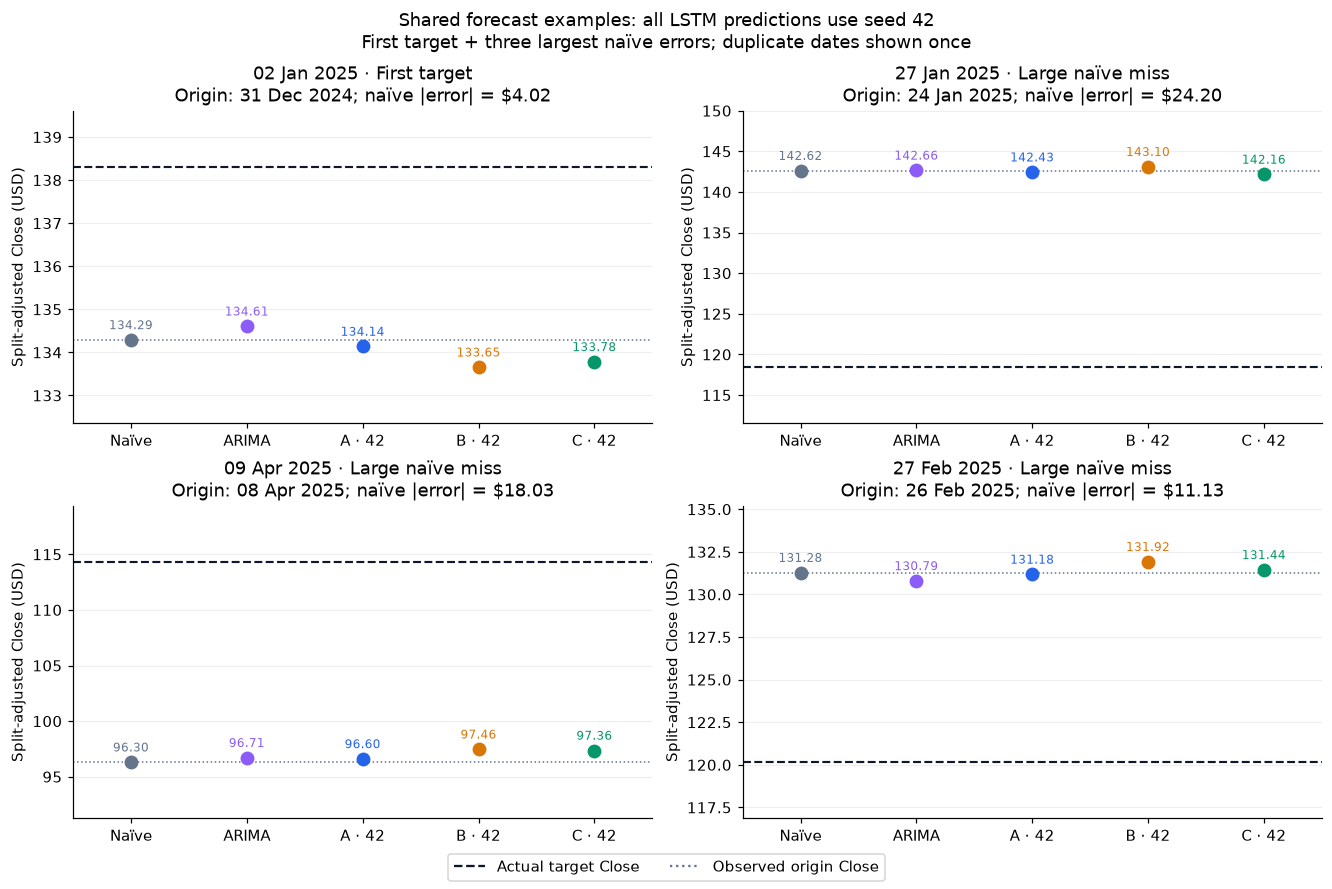

In [7]:
example_dates = [str(date.date()) for date in select_forecast_examples(table)]
assert example_dates == record["illustrative_dates"] == [
    "2025-01-02", "2025-01-27", "2025-04-09", "2025-02-27",
]
assert record["representative_seed"] == 42
plot_forecast_examples(table)
plt.show()

On 2 January, the actual Close was \$138.31 against a naïve forecast of \$134.29. The largest naïve misses were \$24.20 on 27 January, \$18.03 on 9 April and \$11.13 on 27 February. All representative models missed these large movements substantially: their forecasts remained much closer to the previous Close than to the realised target. Some corrections reduced individual errors, but none anticipated the full movements shown.

A forecast that follows yesterday's price can closely resemble the actual price curve over a year, especially when daily changes are small relative to the price level. Such resemblance is not evidence of improvement over persistence. Here, identical-date errors expose the limited advantage hidden by visual overlap. These examples illustrate behaviour rather than establish its cause; no specific market event or model mechanism is inferred from them.

## 6. Uncertainty and statistical interpretation

The predefined paired circular-block bootstrap assesses uncertainty in **MAE differences**, approximately retaining temporal dependence within sampled date blocks. The same blocks are resampled jointly across models and fixed seeds. Settings are 5,000 resamples, seed 314159, approximate 95% percentile intervals, and a primary block length of ten sessions. Five- and twenty-session blocks provide sensitivity checks.

The calculation below verifies the saved intervals using the existing implementation and stored forecasts. It introduces no new statistical test or forecast. Family comparisons use mean seed absolute losses, preserving the distinction from an ensemble.

In [8]:
settings = record["configuration"]["protocol"]["bootstrap"]
block_lengths = (settings["primary_block_length"], *settings["sensitivity_block_lengths"])
assert block_lengths == (10, 5, 20) and settings["resamples"] == 5000 and settings["seed"] == 314159
bootstrap = paired_circular_bootstrap(table, block_lengths, settings["resamples"], settings["seed"])
assert bootstrap == record["bootstrap"]
primary = pd.DataFrame(bootstrap["intervals"]["10"]).T
primary.index.name = "MAE comparison"
for name, interval in bootstrap["intervals"]["10"].items():
    np.testing.assert_allclose(interval["estimate_usd"],
        metrics["paired_comparisons"][name]["mean_mae_difference_usd"], rtol=0, atol=1e-12)
display(primary.rename(columns={"estimate_usd": "Difference (USD)",
                                "lower_usd": "95% lower", "upper_usd": "95% upper"}))

,Difference (USD),95% lower,95% upper
MAE comparison,,,
A-naive,0.032785,-0.000941,0.067761
ARIMA-naive,-0.044630,-0.097268,0.005675
B-A,-0.005649,-0.046286,0.033419
C-B,-0.002771,-0.015055,0.010272


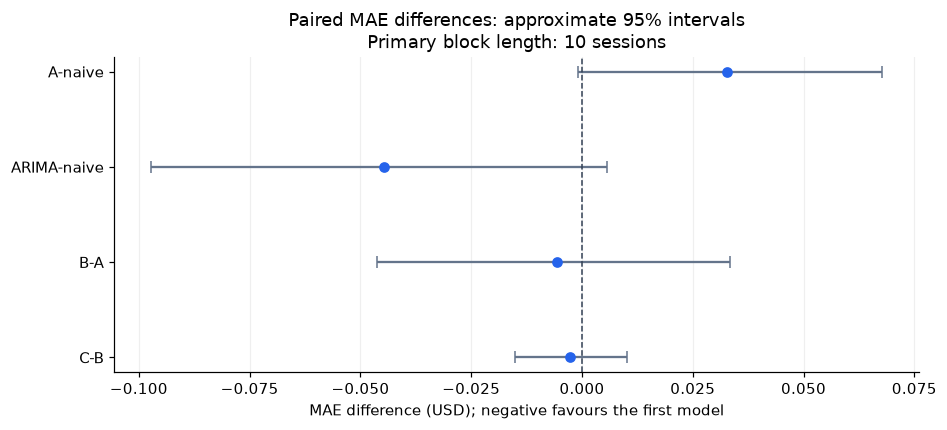

In [9]:
# Plot the recorded interval endpoints; this cell performs no statistical estimation.
fig, ax = plt.subplots(figsize=(8.5, 3.8), layout="constrained")
centres = primary["estimate_usd"].to_numpy()
bounds = np.vstack([centres - primary["lower_usd"], primary["upper_usd"] - centres])
ax.errorbar(centres, np.arange(len(primary)), xerr=bounds,
            fmt="o", color="#2563eb", ecolor="#64748b", capsize=4)
ax.axvline(0, color="#334155", linestyle="--", linewidth=1)
ax.set(yticks=np.arange(len(primary)), yticklabels=primary.index,
       xlabel="MAE difference (USD); negative favours the first model",
       title="Paired MAE differences: approximate 95% intervals\nPrimary block length: 10 sessions")
ax.invert_yaxis()
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.2)
plt.show()

All four primary intervals include zero. ARIMA's interval is approximately [−\$0.097268, +\$0.005675], despite its favourable observed difference. Its superiority is therefore **not statistically established by the primary analysis**. With twenty-session blocks, ARIMA's upper endpoint is narrowly negative (−\$0.000419); the five-session interval includes zero. This sensitivity discourages a strong superiority claim. Both feature contrasts include zero at every prescribed block length.

The intervals are approximate and conditional on these frozen models and this observed year. Circular blocks join the year's end to its beginning; changing market regimes may weaken their dependence assumptions. Seeds remain fixed, and intervals are not adjusted for multiple comparisons. They are neither future price prediction intervals nor guarantees of future performance, and they cannot justify changing the selected methodology.

In [10]:
# Reading, checking and plotting saved evidence must leave every protected input intact.
assert all(hashlib.sha256(path.read_bytes()).hexdigest() == digest
           for path, digest in before_hashes.items())
print("Saved evidence verified; frozen inputs and Notebooks 01–05 are unchanged.")

Saved evidence verified; frozen inputs and Notebooks 01–05 are unchanged.


## 7. Conclusions, limitations and future work

**RQ1:** the selected price-only LSTM did not establish an advantage over naïve persistence or ARIMA. **RQ2:** technical indicators produced small, inconsistent changes, including lower MAE but higher RMSE relative to A. **RQ3:** SPY/XLK slightly improved mean errors relative to B, without surpassing naïve or establishing a reliable benefit. ARIMA achieved the lowest observed errors, but its advantage was modest and uncertainty-sensitive.

The study is limited to one independent test year and three training seeds. Changing price levels and volatility may challenge generalisation, but these comparisons do not identify the cause of particular errors. Correlated indicators and unequal parameter counts complicate attribution. A dollar-correction target reduces the need to predict unfamiliar absolute levels directly; it does not remove distribution shift in absolute-price inputs or stabilise dollar volatility.

A controlled percentage-return target remains possible future work. Squared return errors weight the corresponding dollar errors approximately by the inverse squared origin price, changing the training objective across price levels. Changing the target alone would not resolve absolute-price input shift. This formulation is not implemented or selected here. Any future experiment motivated by these test findings requires a new untouched evaluation period for independent confirmation.

**Final conclusion:** under the frozen protocol, persistence remained a strong benchmark. Neither the selected LSTM nor the engineered feature groups demonstrated a dependable forecasting advantage in this independent assessment.